2.5	Thiết lập môi trường

In [2]:
import sys

print("Python version:", sys.version)
print("Python path:", sys.executable)
print("Classification 2.5 - Ready!")

Python version: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
Python path: c:\Users\QuanTheAnh\anaconda3\python.exe
Classification 2.5 - Ready!


In [3]:
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)

Pandas: 3.0.3
NumPy: 2.4.6
Matplotlib: 3.11.0
Seaborn: 0.13.2
Scikit-learn: 1.9.0



## Bước 2.5.1 – Nạp và kiểm tra dữ liệu đầu vào

**Mục tiêu:** Nạp tập dữ liệu đã qua tiền xử lý từ bước 2.1–2.2, xác nhận đường dẫn, kích thước và cấu trúc dữ liệu trước khi xây dựng mô hình phân lớp.

**Dữ liệu sử dụng:** `clean_data_processed.csv`

**Phương pháp:**
- Sử dụng `pathlib.Path` để xác định đường dẫn dữ liệu.
- Sử dụng `pandas.read_csv()` để đọc dữ liệu.
- Kiểm tra sự tồn tại của file bằng `Path.exists()`.
- Kiểm tra kích thước dữ liệu bằng `df.shape`.
- Hiển thị 5 bản ghi đầu tiên bằng `df.head()`.

**Kết quả:** Nạp thành công tập dữ liệu gồm **3.135 bản ghi và 47 thuộc tính**.

**Lưu ý:** Tập dữ liệu `clean_data.csv` trước đó có 3.204 bản ghi và 41 thuộc tính. Cần đối chiếu quy trình tiền xử lý để xác định nguyên nhân thay đổi số dòng và số cột. Ngoài ra, việc đọc dữ liệu thành công chưa đảm bảo dữ liệu đã phù hợp để huấn luyện mô hình.

**Kết luận:** Dữ liệu đã được nạp thành công, đủ điều kiện để tiếp tục khảo sát nhãn phân lớp và kiểm tra chất lượng dữ liệu.


In [ ]:
from pathlib import Path
import pandas as pd

# Thu muc repository GitHub
PROJECT_ROOT = Path.cwd().resolve().parent

# Du lieu ke thua tu buoc 2.1 - 2.2
DATA_PATH = (
    PROJECT_ROOT
    / "buoc2.1_2.2"
    / "data"
    / "processed"
    / "clean_data_processed.csv"
)

print("Duong dan:", DATA_PATH)
print("File ton tai:", DATA_PATH.is_file())

if DATA_PATH.is_file():
    df = pd.read_csv(DATA_PATH)
    print("Kich thuoc du lieu:", df.shape)
else:
    raise FileNotFoundError(DATA_PATH)

Duong dan: D:\Projects\BaiTapLon_KhaiPhaDuLieu\vietnam-it-job-market-analysis-main\vietnam-it-job-market-analysis-main\buoc2.1_2.2\data\processed\clean_data_processed.csv
File ton tai: True
Kich thuoc du lieu: (3135, 47)


,job_uid,job_group_id,source,URL_Goc,Timestamp,posted_date,posted_date_source,title,company,it_decision_source,...,intern_flag_review,description_clean,has_jd_clean,tech_list,keywords_list,skills,broad_concepts,application_domains,n_skills,text_for_tfidf
0,itviec-b9bccb83ab,g38788d35,itviec,https://itviec.com/it-jobs/manual-quality-assu...,2026-11-17T18:09:16+07:00,11/10/2026,field,Manual Quality Assurance (Senior/Lead),VinSmart Future,filter,...,False,Top 3 Reasons To Join Us Competitive Salary & ...,True,"[""Jira"", ""SQL""]","[""Azure"", ""DevOps""]","[""Azure"", ""DevOps"", ""Jira"", ""SQL""]",[],[],4,reasons join competitive salary benefits train...
1,itviec-ea14bd1d88,gb2b041c2,itviec,https://itviec.com/it-jobs/senior-data-scienti...,2026-11-17T18:09:16+07:00,10/27/2026,field,Senior Data Scientist - GSM Platform,VinSmart Future,filter,...,False,Top 3 Reasons To Join Us Competitive Salary & ...,True,"[""Python"", ""SQL"", ""Spark""]","[""Computer Vision"", ""Machine Learning""]","[""Computer Vision"", ""Machine Learning"", ""Pytho...",[],[],5,reasons join competitive salary benefits train...
2,itviec-99df719b7e,gb9e2c43d,itviec,https://itviec.com/it-jobs/japanese-tester-qa-...,2026-11-17T18:09:16+07:00,11/10/2026,field,Japanese Tester (QA/QC),Kobo Asia,filter,...,False,Top 3 Reasons To Join Us Cùng nhau thử thách v...,True,"[""Git"", ""Jira"", ""SQL"", ""SQL Server""]","[""AI""]","[""Git"", ""Jira"", ""SQL"", ""SQL Server""]","[""AI""]",[],4,reasons join cùng nhau thử thách kĩ thuật mới ...
3,itviec-8f816367b4,g0774918e,itviec,https://itviec.com/it-jobs/senior-application-...,2026-11-17T18:09:16+07:00,11/7/2026,field,Senior Application Operations Engineer (SysOps),Ngân hàng TMCP Tiên Phong | TPBank,filter,...,False,Top 3 Reasons To Join Us Thưởng dự án và thưởn...,True,"[""Kubernetes"", ""Linux""]","[""DevOps""]","[""DevOps"", ""Kubernetes"", ""Linux""]",[],[],3,reasons join thưởng dự án thưởng cuối năm cao ...
4,itviec-2825747e21,gc0b05eb6,itviec,https://itviec.com/it-jobs/ai-engineer-kobo-as...,2026-11-17T18:09:16+07:00,11/10/2026,field,AI Engineer,Kobo Asia,filter,...,False,Top 3 Reasons To Join Us Cùng nhau thử thách v...,True,"["".NET"", ""C#"", ""Docker"", ""Git"", ""GitHub"", ""Git...","[""AI"", ""AWS"", ""CI/CD"", ""DevOps"", ""LLM"", ""Unit ...","["".NET"", ""AWS"", ""C#"", ""CI/CD"", ""DevOps"", ""Dock...","[""AI""]",[],14,reasons join cùng nhau thử thách kĩ thuật mới ...


## Bước 2.5.2 – Khảo sát và lựa chọn nhãn phân lớp

**Mục tiêu:** Khảo sát các thuộc tính có khả năng làm nhãn phân lớp,
đánh giá tỷ lệ thiếu dữ liệu và mức độ mất cân bằng giữa các lớp.

**Nhãn ứng viên:** seniority, work_mode, salary_status,
it_decision, title_role (nếu tồn tại).

**Nguyên tắc:** Ưu tiên nhãn có ý nghĩa thực tiễn, đủ số lượng
mẫu và hạn chế nguy cơ rò rỉ dữ liệu.

In [7]:

# BUOC 2.5.2 - KHAO SAT NHAN PHAN LOP

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Kiem tra du lieu tu buoc 2.5.1
assert "df" in globals(), "Hay chay lai buoc 2.5.1"
print("Kich thuoc du lieu:", df.shape)

# Cac nhan co the su dung cho bai toan phan lop
candidate_targets = [
    "seniority",
    "work_mode",
    "salary_status",
    "it_decision",
    "title_role"
]

available_targets = [
    col for col in candidate_targets
    if col in df.columns
]

print("\nCAC NHAN HIEN CO:")
print(available_targets)

summary = []

for col in available_targets:
    s = df[col].astype("string").str.strip()
    s = s.replace("", pd.NA)

    counts = s.value_counts(dropna=True)

    summary.append({
        "Nhan": col,
        "So_lop": len(counts),
        "So_mau_hop_le": int(s.notna().sum()),
        "So_mau_thieu": int(s.isna().sum()),
        "Ty_le_thieu_%": round(s.isna().mean() * 100, 2),
        "Lop_pho_bien_nhat": str(counts.index[0]) if len(counts) else None,
        "Ty_le_lop_lon_nhat_%": round(
            counts.iloc[0] / counts.sum() * 100, 2
        ) if len(counts) else None
    })

target_summary = pd.DataFrame(summary)

display(target_summary)


Kich thuoc du lieu: (3135, 47)

CAC NHAN HIEN CO:
['salary_status', 'title_role']


,Nhan,So_lop,So_mau_hop_le,So_mau_thieu,Ty_le_thieu_%,Lop_pho_bien_nhat,Ty_le_lop_lon_nhat_%
0,salary_status,8,3135,0,0.0,negotiable,48.55
1,title_role,15,3135,0,0.0,software,18.05


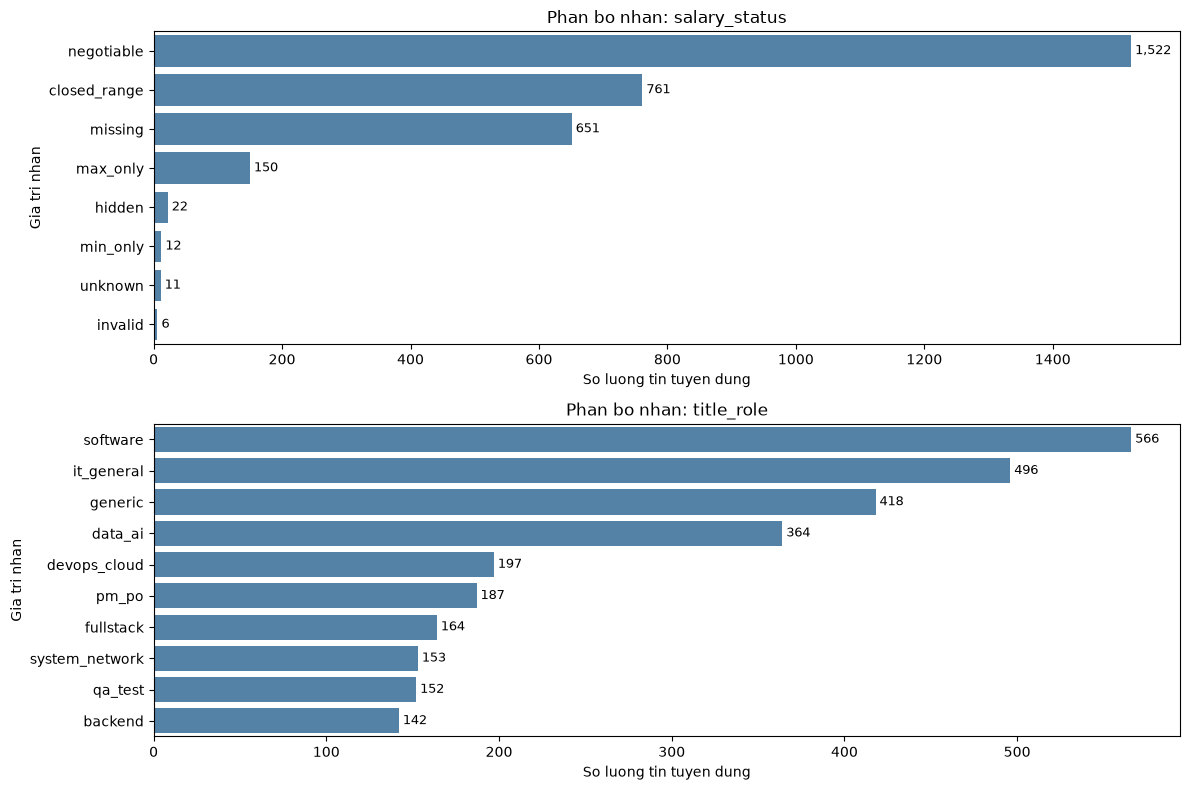

In [8]:

# TRUC QUAN HOA PHAN BO NHAN

if not available_targets:
    print("Khong tim thay nhan ung vien.")
else:
    n = len(available_targets)

    fig, axes = plt.subplots(
        n, 1,
        figsize=(12, 4 * n),
        squeeze=False
    )

    for i, col in enumerate(available_targets):
        ax = axes[i, 0]

        values = (
            df[col]
            .astype("string")
            .str.strip()
            .fillna("Missing")
            .replace("", "Missing")
        )

        counts = values.value_counts().head(10)

        sns.barplot(
            x=counts.values,
            y=counts.index.astype(str),
            ax=ax,
            color="steelblue"
        )

        ax.set_title(f"Phan bo nhan: {col}")
        ax.set_xlabel("So luong tin tuyen dung")
        ax.set_ylabel("Gia tri nhan")

        for j, count in enumerate(counts.values):
            ax.text(
                count,
                j,
                f" {count:,}",
                va="center",
                fontsize=9
            )

    plt.tight_layout()
    plt.show()


## Bước 2.5.3 – Kiểm tra nhãn và đặc trưng cho mô hình

**Mục tiêu:** Kiểm tra phân bố đầy đủ của nhãn title_role,
xác định các cột có nguy cơ rò rỉ nhãn và đánh giá
dữ liệu đầu vào trước khi xây dựng mô hình phân lớp.

In [9]:

# BUOC 2.5.3 - KIEM TRA NHAN VA DAC TRUNG

import pandas as pd

TARGET = "title_role"

# 1. Phan bo day du 15 lop
print("PHAN BO NHAN:")
counts = df[TARGET].value_counts(dropna=False)

distribution = pd.DataFrame({
    "So_luong": counts,
    "Ty_le_%": (counts / len(df) * 100).round(2)
})
display(distribution)

# 2. Kiem tra so mau cua lop nho nhat
print("\nLop nho nhat:", counts.min())

# 3. Danh sach tat ca cot va kieu du lieu
column_info = pd.DataFrame({
    "Cot": df.columns,
    "Kieu_du_lieu": df.dtypes.astype(str).values,
    "So_gia_tri_thieu": df.isna().sum().values,
    "So_gia_tri_phan_biet": df.nunique(dropna=True).values
})
display(column_info)

# 4. Phat hien cac cot co nguy co ro ri nhan
leakage_keywords = [
    "title", "role", "job_uid",
    "job_group_id", "url", "description"
]

suspected_leakage = [
    col for col in df.columns
    if any(word in col.lower() for word in leakage_keywords)
]

print("\nCAC COT CAN XEM XET LOAI TRU:")
print(suspected_leakage)

# 5. Kiem tra trung lap
print("\nSo dong trung lap:", df.duplicated().sum())


PHAN BO NHAN:


,So_luong,Ty_le_%
title_role,,
software,566,18.05
it_general,496,15.82
generic,418,13.33
data_ai,364,11.61
devops_cloud,197,6.28
pm_po,187,5.96
fullstack,164,5.23
system_network,153,4.88
qa_test,152,4.85



Lop nho nhat: 29


,Cot,Kieu_du_lieu,So_gia_tri_thieu,So_gia_tri_phan_biet
0,job_uid,str,0,3135
1,job_group_id,str,0,3135
2,source,str,0,5
3,URL_Goc,str,0,3135
4,Timestamp,str,0,144
5,posted_date,str,0,139
6,posted_date_source,str,0,2
7,title,str,0,2801
8,company,str,1,1509
9,it_decision_source,str,266,2



CAC COT CAN XEM XET LOAI TRU:
['job_uid', 'job_group_id', 'URL_Goc', 'title', 'title_role', 'description_clean']

So dong trung lap: 0



## Bước 2.5.4 – Kiểm tra nhãn và lựa chọn đặc trưng

### 1. Lý do thực hiện

Từ bước 2.5.2 và 2.5.3, dữ liệu có 3.135 tin tuyển dụng với 15 lớp thuộc nhãn `title_role`. Phân bố giữa các lớp không đồng đều, trong đó lớp lớn nhất có 566 mẫu và lớp nhỏ nhất chỉ có 29 mẫu.

Sự chênh lệch này có thể khiến mô hình ưu tiên dự đoán những nhóm nghề nghiệp phổ biến và hoạt động kém trên các nhóm ít mẫu.

Bên cạnh đó, dữ liệu có 47 cột nhưng không phải tất cả đều phù hợp để đưa vào mô hình phân lớp.

### 2. Mục tiêu

- Kiểm tra đầy đủ số lượng và tỷ lệ của 15 lớp.
- Xác định các lớp có ít hơn 50 mẫu.
- Kiểm tra giá trị thiếu và số giá trị phân biệt của các đặc trưng ứng viên.
- Xác định các cột liên quan đến chức danh và nhóm nghề nghiệp.
- Chuẩn bị cơ sở để lựa chọn đặc trưng đầu vào cho mô hình.

### 3. Phương pháp thực hiện

Sử dụng Pandas để thống kê phân bố nhãn `title_role` bằng `value_counts()`.

Tiếp theo, khảo sát các thuộc tính ứng viên như `title`, `description_clean`, `tech`, `keywords`, `seniority` và `salary_status`.

Đồng thời, kiểm tra các cột có tên liên quan đến `role` hoặc `title` để phát hiện nguy cơ rò rỉ thông tin từ nhãn mục tiêu.

### 4. Lưu ý

**Tuy nhiên**, lớp ít mẫu không nhất thiết phải bị loại bỏ hoặc gộp ngay. Cần cân nhắc ý nghĩa nghề nghiệp của từng lớp và mục tiêu phân tích thị trường tuyển dụng.

Các đặc trưng như `title` và `description_clean` có thể chứa thông tin quan trọng cho phân lớp. Ngược lại, những cột được tạo trực tiếp từ nhãn mục tiêu có nguy cơ gây rò rỉ dữ liệu.

Ở bước này chỉ thực hiện khảo sát, chưa loại bỏ cột hoặc thay đổi dữ liệu gốc.

### 5. Kết quả mong đợi

- Bảng phân bố đầy đủ 15 lớp.
- Danh sách các lớp có ít hơn 50 mẫu.
- Thống kê giá trị thiếu và số giá trị phân biệt của các đặc trưng ứng viên.
- Danh sách các cột liên quan đến nhãn nghề nghiệp.

### 6. Ý nghĩa đối với bước tiếp theo

Kết quả bước 2.5.4 là cơ sở để lựa chọn tập đặc trưng X và nhãn mục tiêu y, đồng thời quyết định phương pháp chia dữ liệu và xử lý mất cân bằng lớp trước khi huấn luyện mô hình.


In [10]:

# BƯỚC 2.5.4 - KIỂM TRA NHÃN VÀ ĐẶC TRƯNG

# 1. Thống kê đầy đủ 15 lớp
class_counts = df["title_role"].value_counts()

class_summary = pd.DataFrame({
    "So_luong": class_counts,
    "Ty_le_%": (class_counts / len(df) * 100).round(2)
})

print("=== PHAN BO DAY DU 15 LOP ===")
display(class_summary)

# 2. Kiểm tra các lớp ít hơn 50 mẫu
print("\n=== CAC LOP IT HON 50 MAU ===")
display(class_summary[class_summary["So_luong"] < 50])

# 3. Kiểm tra các cột quan trọng
candidate_cols = [
    "title", "description_clean", "tech",
    "keywords", "seniority", "salary_status",
    "title_role"
]

print("\n=== KIEM TRA CAC COT UNG VIEN ===")

for col in candidate_cols:
    if col in df.columns:
        print(
            f"{col}: "
            f"missing={df[col].isna().sum()}, "
            f"unique={df[col].nunique(dropna=True)}"
        )
    else:
        print(f"{col}: KHONG TON TAI")

# 4. Kiểm tra các cột liên quan đến nhãn
print("\n=== CAC COT LIEN QUAN DEN ROLE ===")
print([
    col for col in df.columns
    if "role" in col.lower()
    or "title" in col.lower()
])


=== PHAN BO DAY DU 15 LOP ===


,So_luong,Ty_le_%
title_role,,
software,566,18.05
it_general,496,15.82
generic,418,13.33
data_ai,364,11.61
devops_cloud,197,6.28
pm_po,187,5.96
fullstack,164,5.23
system_network,153,4.88
qa_test,152,4.85



=== CAC LOP IT HON 50 MAU ===


,So_luong,Ty_le_%
title_role,,
embedded,47,1.50
unknown,40,1.28
frontend,29,0.93



=== KIEM TRA CAC COT UNG VIEN ===
title: missing=0, unique=2801
description_clean: missing=30, unique=3097
tech: KHONG TON TAI
keywords: KHONG TON TAI
seniority: KHONG TON TAI
salary_status: missing=0, unique=8
title_role: missing=0, unique=15

=== CAC COT LIEN QUAN DEN ROLE ===
['title', 'title_role']



## Bước 2.5.5 – Chuẩn bị dữ liệu cho mô hình phân lớp

### 1. Lý do thực hiện

Kết quả bước 2.5.4 cho thấy dữ liệu gồm 15 nhóm nghề nghiệp với mức độ phân bố không đồng đều.

Trong các thuộc tính hiện có, `description_clean` chứa nội dung mô tả tuyển dụng và có khả năng cung cấp đặc trưng văn bản cho mô hình.

### 2. Mục tiêu

- Lựa chọn nhãn mục tiêu `title_role`.
- Lựa chọn `description_clean` làm đặc trưng đầu vào.
- Xử lý các mô tả bị thiếu hoặc rỗng.
- Kiểm tra số lượng mẫu còn lại.
- Chuẩn bị dữ liệu cho bước chia tập train/test.

### 3. Phương pháp

Sử dụng Pandas để tạo bản sao dữ liệu, chuẩn hóa nội dung văn bản và loại bỏ những dòng không có mô tả hợp lệ.

Giữ nguyên các lớp nghề nghiệp trong lần thử nghiệm đầu tiên để có cơ sở so sánh.

### 4. Lưu ý

**Tuy nhiên**, cần xác minh cách tạo nhãn `title_role` ở các bước trước. Nếu nhãn được sinh tự động từ `title`, kết quả phân lớp chỉ phản ánh khả năng dự đoán nhãn tự động, chưa chứng minh khả năng phân loại nghề nghiệp theo nhãn thực tế.

Ngoài ra, việc loại bỏ mô tả thiếu có thể làm thay đổi phân bố lớp. Vì vậy cần kiểm tra lại số lượng mẫu sau xử lý.

### 5. Kết quả mong đợi

Thu được tập dữ liệu có đặc trưng văn bản hợp lệ, không chứa giá trị rỗng và sẵn sàng cho quá trình chia dữ liệu, vector hóa và huấn luyện.


In [11]:

# BUOC 2.5.5 - CHUAN BI DU LIEU PHAN LOP

# 1. Tao ban sao, khong thay doi du lieu goc
df_model = df.copy()

# 2. Chuan hoa cot van ban
df_model["description_clean"] = (
    df_model["description_clean"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# 3. Loai bo mo ta rong
before = len(df_model)

df_model = df_model[
    df_model["description_clean"].str.len() > 0
].copy()

after = len(df_model)

# 4. Xac dinh X va y
X = df_model["description_clean"]
y = df_model["title_role"]

# 5. Thong ke
print("=== CHUAN BI DU LIEU ===")
print("So mau ban dau:", before)
print("So mau con lai:", after)
print("So mau bi loai:", before - after)
print("So lop:", y.nunique())

print("\n=== PHAN BO NHAN SAU XU LY ===")
display(y.value_counts().to_frame("So_luong"))

print("\n=== KIEM TRA ===")
print("Van ban rong:", (X.str.len() == 0).sum())
print("Nhan thieu:", y.isna().sum())
print("Do dai van ban trung vi:", X.str.len().median())


=== CHUAN BI DU LIEU ===
So mau ban dau: 3135
So mau con lai: 3105
So mau bi loai: 30
So lop: 15

=== PHAN BO NHAN SAU XU LY ===


,So_luong
title_role,
software,560
it_general,492
generic,412
data_ai,363
devops_cloud,196
pm_po,187
fullstack,163
system_network,151
qa_test,148



=== KIEM TRA ===
Van ban rong: 0
Nhan thieu: 0
Do dai van ban trung vi: 3106.0



### Bước 2.5.6 – Kiểm tra trùng lặp và nguy cơ rò rỉ dữ liệu

**Mục tiêu:** Kiểm tra tính độc lập giữa các tin tuyển dụng, nguồn gốc nhãn phân lớp và những yếu tố có thể gây rò rỉ dữ liệu trước khi huấn luyện mô hình.

**Kế thừa các bước trước:**
- **2.1–2.2:** Dữ liệu đã được làm sạch, chuẩn hóa và bổ sung các trường phục vụ phân tích.
- **2.3:** Các nhóm nghề nghiệp có thể chồng lấn về đặc trưng, cần đánh giá khả năng phân biệt giữa các lớp.
- **2.4:** Một số kỹ năng thường xuất hiện cùng nhau, nhưng mối liên hệ này chưa chứng minh được khả năng dự đoán nhãn nghề nghiệp.

**Lý do thực hiện:**
1. Một tin tuyển dụng có thể xuất hiện nhiều lần với các `job_uid` khác nhau nhưng cùng `job_group_id`.
2. Nếu các bản ghi cùng nhóm xuất hiện ở cả Train và Test, kết quả đánh giá có thể bị lạc quan.
3. Nhãn `title_role` có thể được tạo từ `title`; cần xác minh quy tắc tạo nhãn để tránh sử dụng các đặc trưng làm lộ trực tiếp đáp án.
4. Cần kiểm tra phân bố nhãn theo nguồn tuyển dụng để phát hiện sự khác biệt giữa các nguồn.

**Lưu ý:** Chưa tự động xóa bản ghi trùng hoặc loại bỏ đặc trưng. Kết quả kiểm tra sẽ được sử dụng để quyết định cách chia dữ liệu và thiết kế mô hình ở bước tiếp theo.


In [12]:

# ==================================================
# 2.5.6 - KIEM TRA TRUNG LAP VA DATA LEAKAGE
# ==================================================

import pandas as pd

# Su dung du lieu da xu ly o buoc 2.5.5
data = df_model.copy()

print("=== 1. TONG QUAN DU LIEU ===")
print("So mau:", len(data))
print("So cot:", data.shape[1])
print("So lop:", data["title_role"].nunique())

# --------------------------------------------------
# 2. KIEM TRA JOB_GROUP_ID
# --------------------------------------------------

print("\n=== 2. KIEM TRA JOB_GROUP_ID ===")

if "job_group_id" in data.columns:
    group = data["job_group_id"]

    print("So group khac nhau:", group.nunique())
    print("Group bi thieu:", group.isna().sum())

    group_counts = group.value_counts()

    print("So group co nhieu hon 1 mau:",
          (group_counts > 1).sum())

    print("So mau thuoc group trung:",
          group_counts[group_counts > 1].sum())

    display(group_counts.head(10))

    # Kiem tra mot group co nhieu nhan khac nhau
    conflict = (
        data.dropna(subset=["job_group_id"])
        .groupby("job_group_id")["title_role"]
        .nunique()
    )

    print("Group co nhieu nhan:",
          (conflict > 1).sum())

else:
    print("Khong co cot job_group_id")

# --------------------------------------------------
# 3. KIEM TRA TRUNG NOI DUNG
# --------------------------------------------------

print("\n=== 3. KIEM TRA TRUNG NOI DUNG ===")

if "description_clean" in data.columns:
    duplicated_text = data[
        "description_clean"
    ].duplicated().sum()

    print("So mo ta trung lap:", duplicated_text)

# --------------------------------------------------
# 4. PHAN BO NHAN THEO NGUON
# --------------------------------------------------

print("\n=== 4. PHAN BO NHAN THEO NGUON ===")

if "source" in data.columns:
    source_role = pd.crosstab(
        data["source"],
        data["title_role"]
    )

    display(source_role)

    source_role_pct = pd.crosstab(
        data["source"],
        data["title_role"],
        normalize="index"
    ) * 100

    print("Ty le nhan theo tung nguon (%):")
    display(source_role_pct.round(2))

# --------------------------------------------------
# 5. KIEM TRA CAC COT CO NGUY CO RO RI
# --------------------------------------------------

print("\n=== 5. KIEM TRA DATA LEAKAGE ===")

suspect_cols = [
    "title",
    "title_role",
    "job_uid",
    "job_group_id",
    "URL_Goc",
    "seniority",
    "seniority_clean",
    "salary_status",
    "description_clean"
]

for col in suspect_cols:
    if col in data.columns:
        print(f"{col}: CO")
    else:
        print(f"{col}: KHONG CO")

# --------------------------------------------------
# 6. KIEM TRA NHAN VA TIEU DE
# --------------------------------------------------

print("\n=== 6. KIEM TRA TITLE VA TITLE_ROLE ===")

if {"title", "title_role"}.issubset(data.columns):
    display(
        data[["title", "title_role"]]
        .sample(
            n=min(15, len(data)),
            random_state=42
        )
    )

print("\nHOAN THANH BUOC 2.5.6")


=== 1. TONG QUAN DU LIEU ===
So mau: 3105
So cot: 47
So lop: 15

=== 2. KIEM TRA JOB_GROUP_ID ===
So group khac nhau: 3105
Group bi thieu: 0
So group co nhieu hon 1 mau: 0
So mau thuoc group trung: 0


job_group_id
g38788d35    1
gb2b041c2    1
gb9e2c43d    1
g0774918e    1
gc0b05eb6    1
g3484c6f7    1
gcd770fe1    1
g9713daae    1
g0d89b9ab    1
g6a42922e    1
Name: count, dtype: int64

Group co nhieu nhan: 0

=== 3. KIEM TRA TRUNG NOI DUNG ===
So mo ta trung lap: 8

=== 4. PHAN BO NHAN THEO NGUON ===


title_role,backend,data_ai,devops_cloud,embedded,frontend,fullstack,generic,it_general,mobile,pm_po,qa_test,security,software,system_network,unknown
source,,,,,,,,,,,,,,,
itviec,40,83,55,8,7,40,40,69,16,32,36,17,87,17,18
linkedin,39,92,63,19,7,51,96,44,27,0,16,11,193,1,0
topcv,41,107,56,14,10,50,174,243,33,115,73,44,219,93,0
topdev,3,10,4,0,1,4,9,12,2,3,4,1,7,2,3
vietnamworks,16,71,18,6,3,18,93,124,8,37,19,20,54,38,19


Ty le nhan theo tung nguon (%):


title_role,backend,data_ai,devops_cloud,embedded,frontend,fullstack,generic,it_general,mobile,pm_po,qa_test,security,software,system_network,unknown
source,,,,,,,,,,,,,,,
itviec,7.08,14.69,9.73,1.42,1.24,7.08,7.08,12.21,2.83,5.66,6.37,3.01,15.40,3.01,3.19
linkedin,5.92,13.96,9.56,2.88,1.06,7.74,14.57,6.68,4.10,0.00,2.43,1.67,29.29,0.15,0.00
topcv,3.22,8.41,4.40,1.10,0.79,3.93,13.68,19.10,2.59,9.04,5.74,3.46,17.22,7.31,0.00
topdev,4.62,15.38,6.15,0.00,1.54,6.15,13.85,18.46,3.08,4.62,6.15,1.54,10.77,3.08,4.62
vietnamworks,2.94,13.05,3.31,1.10,0.55,3.31,17.10,22.79,1.47,6.80,3.49,3.68,9.93,6.99,3.49



=== 5. KIEM TRA DATA LEAKAGE ===
title: CO
title_role: CO
job_uid: CO
job_group_id: CO
URL_Goc: CO
seniority: KHONG CO
seniority_clean: CO
salary_status: CO
description_clean: CO

=== 6. KIEM TRA TITLE VA TITLE_ROLE ===


,title,title_role
466,DevSecOps Engineer,devops_cloud
2788,Kỹ Sư Cầu Nối (BrSE),generic
438,"Engineering Manager – Cloud Platform (CI/CD, E...",devops_cloud
2507,Tester Team Lead,qa_test
2056,Mobile IOS Developer Lead,mobile
170,"Senior Backend Developer (Golang, Java, NodeJS)",backend
2501,Chuyên Viên Kỹ Sư Phần Mềm,software
370,"AI Engineer (LLM, Python, Docker, API, RAG)",data_ai
553,Senior IT Business Analyst,it_general
673,"Assistant Manager, Full Stack Software Engineer",fullstack



HOAN THANH BUOC 2.5.6



### Bước 2.5.7 – Thiết kế dữ liệu phân lớp và kiểm soát rò rỉ

**Mục tiêu:** Xây dựng tập đặc trưng X và nhãn y để chuẩn bị huấn luyện Decision Tree, Random Forest.

**Kết quả kế thừa 2.5.6:**
- 3.105 mẫu hợp lệ, 15 lớp nghề nghiệp.
- 3.105 `job_group_id` duy nhất, không có nhóm trùng.
- Phát hiện 8 mô tả trùng lặp cần kiểm tra.
- Phân bố nhãn khác nhau giữa 5 nguồn tuyển dụng.
- `title_role` có liên hệ với `title`, tiềm ẩn nguy cơ rò rỉ nhãn.

**Ý tưởng lựa chọn đặc trưng:**
- Nhãn y: `title_role`.
- Đặc trưng chính: nội dung mô tả công việc (`description_clean`) sau khi chuyển thành TF-IDF.
- Không sử dụng `title`, `job_uid`, `job_group_id`, URL và `title_role` làm đặc trưng.
- Không sử dụng `source` trong baseline chính để hạn chế mô hình phụ thuộc vào nguồn thu thập.
- Chưa sử dụng các trường có nguy cơ được suy ra từ tiêu đề hoặc từ nhãn.

**Tuy nhiên:**
- TF-IDF có thể tạo ra số lượng đặc trưng lớn, cần giới hạn số từ và cụm từ.
- Một số mô tả trùng nhau có thể gây rò rỉ giữa Train/Test.
- Nhãn nghề nghiệp mất cân bằng nên cần chia dữ liệu có phân tầng và đánh giá bằng Macro F1.

**Kết quả mong đợi:** Tập dữ liệu phân lớp rõ ràng, hạn chế rò rỉ và có thể tái lập để so sánh công bằng các mô hình.


In [13]:

# ==================================================
# 2.5.7 - THIET KE X, y VA KIEM TRA TRUNG LAP
# ==================================================

import pandas as pd

data = df_model.copy()

# 1. Kiem tra cot bat buoc
required = ["title_role", "description_clean"]
missing = [c for c in required if c not in data.columns]

if missing:
    raise ValueError(f"Thieu cot: {missing}")

print("=== 1. DU LIEU BAN DAU ===")
print("So mau:", len(data))

# 2. Kiem tra mo ta trung lap
print("\n=== 2. MO TA TRUNG LAP ===")

text = data["description_clean"].fillna("").astype(str).str.strip()

duplicates = data.loc[
    text.duplicated(keep=False)
].copy()

print("So ban ghi nam trong nhom trung:",
      len(duplicates))

if len(duplicates) > 0:
    cols = [
        c for c in
        ["job_uid", "title", "title_role", "source"]
        if c in duplicates.columns
    ]
    display(duplicates[cols].head(20))

# 3. Kiem tra nhan mau trung
print("\n=== 3. KIEM TRA XUNG DOT NHAN ===")

check = pd.DataFrame({
    "text": text,
    "label": data["title_role"]
})

conflicts = check.groupby("text")["label"].nunique()

print("So nhom mo ta co nhieu nhan:",
      (conflicts > 1).sum())

# 4. Chuan bi X va y
print("\n=== 4. TAO X VA y ===")

valid = (
    text.ne("")
    & data["title_role"].notna()
)

X = text.loc[valid].copy()
y = data.loc[valid, "title_role"].copy()

print("So mau X:", len(X))
print("So nhan y:", len(y))
print("So lop:", y.nunique())

print("\nPhan bo nhan:")
display(y.value_counts().to_frame("So_luong"))

print("\nHOAN THANH BUOC 2.5.7")


=== 1. DU LIEU BAN DAU ===
So mau: 3105

=== 2. MO TA TRUNG LAP ===
So ban ghi nam trong nhom trung: 15


,job_uid,title,title_role,source
146,itviec-e9f8dcad33,[Ho Chi Minh] Technical Architect,it_general,itviec
247,itviec-c5d8d94f09,[Da Nang] Technical Architect,it_general,itviec
396,itviec-20f9675b1f,Product Business Analyst,data_ai,itviec
476,itviec-43b5a9b323,Chuyên viên Sản Phẩm (PHÂN TÍCH NGHIỆP VỤ & TH...,data_ai,itviec
593,linkedin-4e3d45d77f,Software Engineer I,software,linkedin
605,linkedin-b26318c893,Backend Software Engineer,backend,linkedin
722,linkedin-1f74ffa33b,System Development Engineer,generic,linkedin
902,linkedin-d15749868d,"C++ Engineer (HMI,Qt - Embedded)",embedded,linkedin
997,linkedin-71cf87f699,DevOps Engineer,devops_cloud,linkedin
1027,linkedin-3c0088010f,"HMI Engineer (C++, Qt)",software,linkedin



=== 3. KIEM TRA XUNG DOT NHAN ===
So nhom mo ta co nhieu nhan: 3

=== 4. TAO X VA y ===
So mau X: 3105
So nhan y: 3105
So lop: 15

Phan bo nhan:


,So_luong
title_role,
software,560
it_general,492
generic,412
data_ai,363
devops_cloud,196
pm_po,187
fullstack,163
system_network,151
qa_test,148



HOAN THANH BUOC 2.5.7



### Bước 2.5.8 – Chia Train/Test và xây dựng mô hình baseline

**Mục tiêu:** Chia dữ liệu thành tập huấn luyện và kiểm tra, xây dựng mô hình DummyClassifier làm mốc so sánh cho Decision Tree và Random Forest.

**Kết quả kế thừa:**
- 3.105 mẫu hợp lệ thuộc 15 lớp nghề nghiệp.
- Có 15 bản ghi thuộc các nhóm mô tả trùng lặp.
- Có 3 nhóm mô tả giống nhau nhưng mang nhiều nhãn khác nhau.
- Dữ liệu mất cân bằng giữa các lớp.

**Lý do thực hiện:**
1. Train/Test phải độc lập để đánh giá khả năng tổng quát hóa.
2. Các bản ghi có cùng mô tả phải nằm trong cùng một tập để tránh rò rỉ nội dung.
3. DummyClassifier giúp xác định mô hình học máy có tốt hơn phương pháp dự đoán đơn giản hay không.
4. Macro F1 được ưu tiên vì đánh giá đồng đều giữa các lớp, kể cả lớp ít mẫu.

**Tuy nhiên:** Chia theo nhóm mô tả không bảo đảm tỷ lệ nhãn chính xác như Stratified Split. Cần kiểm tra số lượng lớp trong cả Train và Test sau khi chia.

**Kết quả mong đợi:** Hai tập Train/Test không trùng mô tả và kết quả baseline dùng làm chuẩn so sánh cho các mô hình tiếp theo.


In [14]:

# ==================================================
# 2.5.8 - TRAIN/TEST SPLIT + DUMMY CLASSIFIER
# ==================================================

import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# 1. Lay X, y tu buoc 2.5.7
X = X.copy()
y = y.copy()

# 2. Tao nhom theo noi dung mo ta
groups = X.astype(str).str.strip()

# 3. Chia theo nhom, tranh trung mo ta
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("=== 1. KICH THUOC TAP DU LIEU ===")
print("Train:", len(X_train))
print("Test:", len(X_test))

# 4. Kiem tra trung mo ta
overlap = set(X_train) & set(X_test)

print("\n=== 2. KIEM TRA RO RI ===")
print("So mo ta trung Train/Test:", len(overlap))

# 5. Kiem tra phan bo nhan
distribution = pd.DataFrame({
    "Train": y_train.value_counts(),
    "Test": y_test.value_counts()
}).fillna(0).astype(int)

print("\n=== 3. PHAN BO NHAN ===")
display(distribution)

# 6. DummyClassifier
dummy = DummyClassifier(
    strategy="most_frequent",
    random_state=42
)

# DummyClassifier chi can ma tran dau vao gia
X_train_dummy = pd.DataFrame(
    {"constant": [0] * len(X_train)}
)
X_test_dummy = pd.DataFrame(
    {"constant": [0] * len(X_test)}
)

dummy.fit(X_train_dummy, y_train)
y_pred_dummy = dummy.predict(X_test_dummy)

# 7. Danh gia baseline
baseline_accuracy = accuracy_score(
    y_test, y_pred_dummy
)

baseline_f1 = f1_score(
    y_test,
    y_pred_dummy,
    average="macro",
    zero_division=0
)

print("\n=== 4. BASELINE DUMMY CLASSIFIER ===")
print("Accuracy:", round(baseline_accuracy, 4))
print("Macro F1:", round(baseline_f1, 4))

print("\n=== 5. CLASSIFICATION REPORT ===")
print(classification_report(
    y_test,
    y_pred_dummy,
    zero_division=0
))

print("\nHOAN THANH BUOC 2.5.8")


=== 1. KICH THUOC TAP DU LIEU ===
Train: 2484
Test: 621

=== 2. KIEM TRA RO RI ===
So mo ta trung Train/Test: 0

=== 3. PHAN BO NHAN ===


,Train,Test
title_role,,
backend,112,27
data_ai,295,68
devops_cloud,156,40
embedded,37,10
frontend,20,8
fullstack,131,32
generic,330,82
it_general,403,89
mobile,71,15



=== 4. BASELINE DUMMY CLASSIFIER ===
Accuracy: 0.1787
Macro F1: 0.0202

=== 5. CLASSIFICATION REPORT ===
                precision    recall  f1-score   support

       backend       0.00      0.00      0.00        27
       data_ai       0.00      0.00      0.00        68
  devops_cloud       0.00      0.00      0.00        40
      embedded       0.00      0.00      0.00        10
      frontend       0.00      0.00      0.00         8
     fullstack       0.00      0.00      0.00        32
       generic       0.00      0.00      0.00        82
    it_general       0.00      0.00      0.00        89
        mobile       0.00      0.00      0.00        15
         pm_po       0.00      0.00      0.00        50
       qa_test       0.00      0.00      0.00        31
      security       0.00      0.00      0.00        24
      software       0.18      1.00      0.30       111
system_network       0.00      0.00      0.00        29
       unknown       0.00      0.00      0.00        


### Bước 2.5.9 – Huấn luyện Decision Tree và tối ưu cắt tỉa cây

**Mục tiêu:** Xây dựng mô hình Decision Tree phân loại 15 nhóm nghề nghiệp dựa trên nội dung mô tả tuyển dụng.

**Kế thừa từ các bước trước:**
- 2.5.7: Xây dựng X từ `description_clean` và y từ `title_role`.
- 2.5.8: Chia Train/Test theo nhóm mô tả, không phát hiện mô tả trùng giữa hai tập.
- Baseline DummyClassifier: Accuracy = 0.1787, Macro F1 = 0.0202.

**Ý tưởng:**
1. Chuyển văn bản thành vector số bằng TF-IDF.
2. Sử dụng Decision Tree để học quy tắc phân loại nghề nghiệp.
3. Kiểm soát `max_depth`, `min_samples_leaf` và `ccp_alpha` nhằm giảm overfitting.
4. Tối ưu tham số bằng cross-validation trên tập Train.
5. Đánh giá trên Test và so sánh với DummyClassifier.

**Tuy nhiên:**
- TF-IDF có số chiều lớn và dữ liệu thưa, Decision Tree có thể bị overfitting.
- Các lớp có số mẫu ít dễ bị dự đoán sai.
- Không được sử dụng tập Test để lựa chọn siêu tham số.
- Kết quả cần được đánh giá bằng cả Accuracy và Macro F1.

**Kết quả mong đợi:** Mô hình Decision Tree được tối ưu, có thể so sánh với baseline và Random Forest ở bước tiếp theo.


In [15]:

# ==================================================
# 2.5.9 - DECISION TREE + TF-IDF + CROSS VALIDATION
# ==================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedGroupKFold
)
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# 1. Tao Pipeline
dt_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=3000,
        min_df=3,
        max_df=0.95,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("model", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

# 2. Khong gian tham so
param_grid = {
    "model__max_depth": [10, 20, 30, None],
    "model__min_samples_leaf": [2, 5, 10],
    "model__ccp_alpha": [0.0, 0.0001, 0.001]
}

# 3. Cross-validation theo nhom mo ta
cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# 4. Grid Search
grid_dt = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("Dang toi uu Decision Tree...")

grid_dt.fit(
    X_train,
    y_train,
    groups=X_train.astype(str).str.strip()
)

# 5. Mo hinh tot nhat
best_dt = grid_dt.best_estimator_

print("\n=== THAM SO TOT NHAT ===")
print(grid_dt.best_params_)

print("\nBest CV Macro F1:",
      round(grid_dt.best_score_, 4))

# 6. Du doan
y_pred_dt = best_dt.predict(X_test)
y_train_pred_dt = best_dt.predict(X_train)

# 7. Danh gia
dt_accuracy = accuracy_score(
    y_test, y_pred_dt
)

dt_f1 = f1_score(
    y_test,
    y_pred_dt,
    average="macro",
    zero_division=0
)

dt_train_f1 = f1_score(
    y_train,
    y_train_pred_dt,
    average="macro",
    zero_division=0
)

print("\n=== KET QUA DECISION TREE ===")
print("Train Macro F1:", round(dt_train_f1, 4))
print("Test Accuracy:", round(dt_accuracy, 4))
print("Test Macro F1:", round(dt_f1, 4))

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_test,
    y_pred_dt,
    zero_division=0
))

# 8. So sanh baseline
comparison = pd.DataFrame({
    "Model": ["DummyClassifier", "Decision Tree"],
    "Accuracy": [baseline_accuracy, dt_accuracy],
    "Macro_F1": [baseline_f1, dt_f1]
})

print("\n=== SO SANH BASELINE ===")
display(comparison)

print("\nHOAN THANH BUOC 2.5.9")


Dang toi uu Decision Tree...
Fitting 3 folds for each of 36 candidates, totalling 108 fits

=== THAM SO TOT NHAT ===
{'model__ccp_alpha': 0.001, 'model__max_depth': None, 'model__min_samples_leaf': 5}

Best CV Macro F1: 0.3541

=== KET QUA DECISION TREE ===
Train Macro F1: 0.6838
Test Accuracy: 0.3688
Test Macro F1: 0.3567

=== CLASSIFICATION REPORT ===
                precision    recall  f1-score   support

       backend       0.25      0.41      0.31        27
       data_ai       0.55      0.44      0.49        68
  devops_cloud       0.58      0.62      0.60        40
      embedded       0.41      0.90      0.56        10
      frontend       0.00      0.00      0.00         8
     fullstack       0.26      0.41      0.32        32
       generic       0.32      0.30      0.31        82
    it_general       0.26      0.16      0.20        89
        mobile       0.38      0.80      0.51        15
         pm_po       0.53      0.62      0.57        50
       qa_test       0.45  

,Model,Accuracy,Macro_F1
0,DummyClassifier,0.178744,0.020219
1,Decision Tree,0.368760,0.356684



HOAN THANH BUOC 2.5.9


### Bước 2.5.9.1 – Tìm tên biến mô hình

In [17]:
# Tìm các biến liên quan đến Decision Tree và GridSearchCV
for name, value in globals().copy().items():
    if any(key in name.lower() for key in ["tree", "grid", "search", "model"]):
        print(name, ":", type(value).__name__)

df_model : DataFrame
DecisionTreeClassifier : ABCMeta
GridSearchCV : ABCMeta
param_grid : dict
grid_dt : GridSearchCV


### Bước 2.5.9.2 – Kiểm tra bổ sung Decision Tree

In [21]:
# BƯỚC 2.5.9 - KIỂM TRA BỔ SUNG DECISION TREE

from sklearn.metrics import f1_score, accuracy_score
import pandas as pd

# Đổi best_tree nếu mô hình tối ưu trong cell trước có tên khác
tree_model = grid_dt.best_estimator_
# Dự đoán
y_train_pred = tree_model.predict(X_train)
y_test_pred = tree_model.predict(X_test)

# Đánh giá
train_f1 = f1_score(y_train, y_train_pred, average="macro")
test_f1 = f1_score(y_test, y_test_pred, average="macro")

summary_tree = pd.DataFrame({
    "Chi_so": [
        "Train Macro F1",
        "Test Macro F1",
        "Overfitting Gap",
        "Test Accuracy"
    ],
    "Gia_tri": [
        train_f1,
        test_f1,
        train_f1 - test_f1,
        accuracy_score(y_test, y_test_pred)
    ]
})

display(summary_tree.round(4))

# Nếu mô hình nằm trong Pipeline
if hasattr(tree_model, "named_steps"):
    dt = tree_model.named_steps["model"]
else:
    dt = tree_model

print("Do sau cua cay:", dt.get_depth())
print("So nut la:", dt.get_n_leaves())
print("So nut:", dt.tree_.node_count)

,Chi_so,Gia_tri
0,Train Macro F1,0.6838
1,Test Macro F1,0.3567
2,Overfitting Gap,0.3271
3,Test Accuracy,0.3688


Do sau cua cay: 40
So nut la: 182
So nut: 363


## Bước 2.5.10 – Huấn luyện và tối ưu Random Forest

### Mục tiêu
Xây dựng mô hình Random Forest nhằm cải thiện khả năng phân loại 15 nhóm nghề nghiệp IT, đồng thời đánh giá liệu mô hình tổ hợp có khắc phục được một phần hạn chế của Decision Tree hay không.

### Cơ sở lựa chọn
Ở bước 2.5.9, Decision Tree đạt Test Macro F1 = 0,3567 nhưng có chênh lệch Train–Test Macro F1 = 0,3271, cho thấy dấu hiệu overfitting.

Random Forest kết hợp nhiều cây quyết định để tạo dự đoán cuối cùng, giúp kiểm tra khả năng cải thiện hiệu suất và độ ổn định.

### Phương pháp
- Sử dụng lại tập Train/Test của bước 2.5.8.
- Giữ nguyên các đặc trưng đầu vào và quy trình tiền xử lý.
- Huấn luyện RandomForestClassifier.
- Tối ưu `n_estimators`, `max_depth`, `min_samples_leaf` bằng GridSearchCV.
- Sử dụng 3-fold cross-validation với Macro F1 làm tiêu chí tối ưu.
- So sánh với DummyClassifier và Decision Tree.

**Lưu ý:** Không sử dụng tập Test để lựa chọn tham số. Các phép tiền xử lý cần học từ dữ liệu phải được thực hiện trong Pipeline để hạn chế data leakage.

In [22]:
# ==================================================
# BƯỚC 2.5.10 - RANDOM FOREST
# ==================================================

import pandas as pd

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# 1. Kế thừa Pipeline từ Decision Tree
# Giữ nguyên các bước tiền xử lý dữ liệu

rf_pipeline = clone(grid_dt.best_estimator_)

# 2. Thay Decision Tree bằng Random Forest

rf_pipeline.set_params(
    model=RandomForestClassifier(
        random_state=42,
        n_jobs=1,
        class_weight="balanced_subsample"
    )
)

# 3. Thiết lập không gian tham số

param_grid_rf = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 20, 40],
    "model__min_samples_leaf": [1, 3, 5]
}

# 4. Tối ưu bằng GridSearchCV

grid_rf = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid_rf,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("Dang toi uu Random Forest...")

grid_rf.fit(X_train, y_train)

# 5. Lấy mô hình tốt nhất

best_rf = grid_rf.best_estimator_

print("\n=== THAM SO TOT NHAT ===")
print(grid_rf.best_params_)

print("\nBest CV Macro F1:",
      round(grid_rf.best_score_, 4))

# 6. Dự đoán Train/Test

rf_train_pred = best_rf.predict(X_train)
rf_test_pred = best_rf.predict(X_test)

# 7. Tính các chỉ số đánh giá

rf_train_f1 = f1_score(
    y_train, rf_train_pred, average="macro"
)

rf_test_f1 = f1_score(
    y_test, rf_test_pred, average="macro"
)

rf_test_acc = accuracy_score(
    y_test, rf_test_pred
)

print("\n=== KET QUA RANDOM FOREST ===")
print("Train Macro F1:", round(rf_train_f1, 4))
print("Test Accuracy:", round(rf_test_acc, 4))
print("Test Macro F1:", round(rf_test_f1, 4))
print("Overfitting Gap:",
      round(rf_train_f1 - rf_test_f1, 4))

# 8. Báo cáo phân loại

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_test,
    rf_test_pred,
    zero_division=0
))

# 9. So sánh với các mô hình trước

comparison_rf = pd.DataFrame({
    "Model": [
        "DummyClassifier",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        0.1787,
        0.3688,
        rf_test_acc
    ],
    "Macro_F1": [
        0.0202,
        0.3567,
        rf_test_f1
    ]
})

print("\n=== SO SANH 3 MO HINH ===")
display(comparison_rf.round(4))

Dang toi uu Random Forest...
Fitting 3 folds for each of 18 candidates, totalling 54 fits

=== THAM SO TOT NHAT ===
{'model__max_depth': 40, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}

Best CV Macro F1: 0.4495

=== KET QUA RANDOM FOREST ===
Train Macro F1: 0.8995
Test Accuracy: 0.5797
Test Macro F1: 0.5474
Overfitting Gap: 0.3521

=== CLASSIFICATION REPORT ===
                precision    recall  f1-score   support

       backend       0.48      0.56      0.52        27
       data_ai       0.69      0.87      0.77        68
  devops_cloud       0.71      0.88      0.79        40
      embedded       0.53      1.00      0.69        10
      frontend       1.00      0.12      0.22         8
     fullstack       0.55      0.81      0.66        32
       generic       0.53      0.45      0.49        82
    it_general       0.44      0.31      0.37        89
        mobile       0.62      0.87      0.72        15
         pm_po       0.70      0.80      0.75        50
     

,Model,Accuracy,Macro_F1
0,DummyClassifier,0.1787,0.0202
1,Decision Tree,0.3688,0.3567
2,Random Forest,0.5797,0.5474



### Bước 2.5.10.1 – Kiểm tra độ ổn định Cross-Validation và độ phức tạp Random Forest


In [23]:
import pandas as pd
import numpy as np

# Kiểm tra kết quả Cross-validation
cv_results = pd.DataFrame(grid_rf.cv_results_)

best_idx = grid_rf.best_index_

print("=== KET QUA TUNG FOLD ===")
for i in range(grid_rf.n_splits_):
    score = cv_results.loc[best_idx, f"split{i}_test_score"]
    print(f"Fold {i+1}: {score:.4f}")

print("\nCV Mean:", round(grid_rf.best_score_, 4))
print("CV Std:", round(
    cv_results.loc[best_idx, "std_test_score"], 4
))

# Kiểm tra cấu trúc Random Forest
rf_model = grid_rf.best_estimator_.named_steps["model"]

depths = [tree.get_depth() for tree in rf_model.estimators_]
leaves = [tree.get_n_leaves() for tree in rf_model.estimators_]

print("\n=== CAU TRUC RANDOM FOREST ===")
print("So cay:", len(rf_model.estimators_))
print("Do sau trung binh:", round(np.mean(depths), 2))
print("So nut la trung binh:", round(np.mean(leaves), 2))

=== KET QUA TUNG FOLD ===
Fold 1: 0.4213
Fold 2: 0.5092
Fold 3: 0.4180

CV Mean: 0.4495
CV Std: 0.0422

=== CAU TRUC RANDOM FOREST ===
So cay: 200
Do sau trung binh: 39.47
So nut la trung binh: 234.66



### Bước 2.5.11 – Đánh giá chi tiết và phân tích lỗi mô hình

**Mục tiêu:**
- So sánh kết quả của DummyClassifier, Decision Tree và Random Forest.
- Phân tích Precision, Recall, F1-score theo từng nhóm nghề.
- Trực quan hóa Confusion Matrix để xác định các nhóm nghề dễ bị nhầm lẫn.
- Kiểm tra mức độ overfitting và đánh giá khả năng tổng quát hóa.

**Lý do thực hiện:**

Random Forest đạt Test Macro F1 = 0.5474, cao hơn Decision Tree (0.3567). Tuy nhiên, Train Macro F1 = 0.8995 cho thấy khoảng cách đáng kể giữa kết quả huấn luyện và kiểm tra.

Vì vậy, cần đánh giá chi tiết để xác định:
1. Những nhóm nghề được dự đoán tốt và chưa tốt.
2. Những cặp nhóm nghề thường bị nhầm lẫn.
3. Mức độ cải thiện so với baseline.
4. Các hạn chế cần ghi nhận trước khi kết luận.

**Lưu ý:**

Kết quả hiện tại sử dụng 15 nhóm nghề (`title_role`), không phải bài toán phân loại Junior/Middle/Senior. Do đó, phân tích lỗi phải dựa trên các nhóm nghề thực tế.

Tập Test chỉ được dùng để đánh giá, không sử dụng để tiếp tục lựa chọn siêu tham số.


In [26]:

# KIEM TRA TEN BIEN MO HINH DA HUAN LUYEN

for name, value in globals().copy().items():
    if any(key in name.lower() for key in [
        "dummy", "grid", "tree", "forest",
        "rf", "dt", "baseline", "model"
    ]):
        print(name, ":", type(value).__name__)


df_model : DataFrame
DummyClassifier : type
dummy : DummyClassifier
X_train_dummy : DataFrame
X_test_dummy : DataFrame
y_pred_dummy : ndarray
baseline_accuracy : float
baseline_f1 : float
DecisionTreeClassifier : ABCMeta
GridSearchCV : ABCMeta
dt_pipeline : Pipeline
param_grid : dict
grid_dt : GridSearchCV
best_dt : Pipeline
y_pred_dt : ndarray
y_train_pred_dt : ndarray
dt_accuracy : float
dt_f1 : float
dt_train_f1 : float
tree_model : Pipeline
summary_tree : DataFrame
dt : DecisionTreeClassifier
RandomForestClassifier : ABCMeta
rf_pipeline : Pipeline
param_grid_rf : dict
grid_rf : GridSearchCV
best_rf : Pipeline
rf_train_pred : ndarray
rf_test_pred : ndarray
rf_train_f1 : float
rf_test_f1 : float
rf_test_acc : float
comparison_rf : DataFrame
rf_model : RandomForestClassifier


In [29]:

# KIEM TRA MO HINH RANDOM FOREST DA TOI UU

for name, value in globals().copy().items():
    if hasattr(value, "best_estimator_"):
        print(
            "Bien:", name,
            "| Loai:", type(value).__name__,
            "| Best estimator:", type(value.best_estimator_).__name__
        )


Bien: grid_dt | Loai: GridSearchCV | Best estimator: Pipeline
Bien: grid_rf | Loai: GridSearchCV | Best estimator: Pipeline


In [33]:

# BUOC 2.5.11.1 - SO SANH CHI TIET 3 MO HINH

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Lay Pipeline da huan luyen va toi uu
best_dt = grid_dt.best_estimator_
best_rf = grid_rf.best_estimator_

# 2. Du doan tren tap Test
predictions = {
    "DummyClassifier": dummy.predict(X_test_dummy),
    "Decision Tree": best_dt.predict(X_test),
    "Random Forest": best_rf.predict(X_test)
}

# 3. Tinh cac chi so danh gia
results = []

for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        )
    })

# 4. Tao bang so sanh
comparison_df = pd.DataFrame(results)

comparison_df = (
    comparison_df
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

print("=== SO SANH CHI TIET 3 MO HINH ===")
display(comparison_df.round(4))


=== SO SANH CHI TIET 3 MO HINH ===


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Random Forest,0.5797,0.5634,0.6148,0.5474,0.5541
1,Decision Tree,0.3688,0.3359,0.4123,0.3567,0.3598
2,DummyClassifier,0.1787,0.0119,0.0667,0.0202,0.0542



### Bước 2.5.11.2 – Trực quan hóa ma trận nhầm lẫn

**Mục đích:** Đánh giá khả năng phân biệt 15 nhóm nghề của Random Forest thông qua Confusion Matrix.

**Lý do:** Mặc dù Random Forest đạt Accuracy 57,97% và Macro F1 0,5474, các chỉ số tổng hợp chưa cho biết mô hình thường nhầm lẫn giữa những nhóm nghề nào.

**Lưu ý:** Các lớp có ít mẫu như frontend, embedded có thể cho kết quả thiếu ổn định. Cần xem xét cả số lượng dự đoán sai và tỷ lệ dự đoán đúng theo từng lớp.


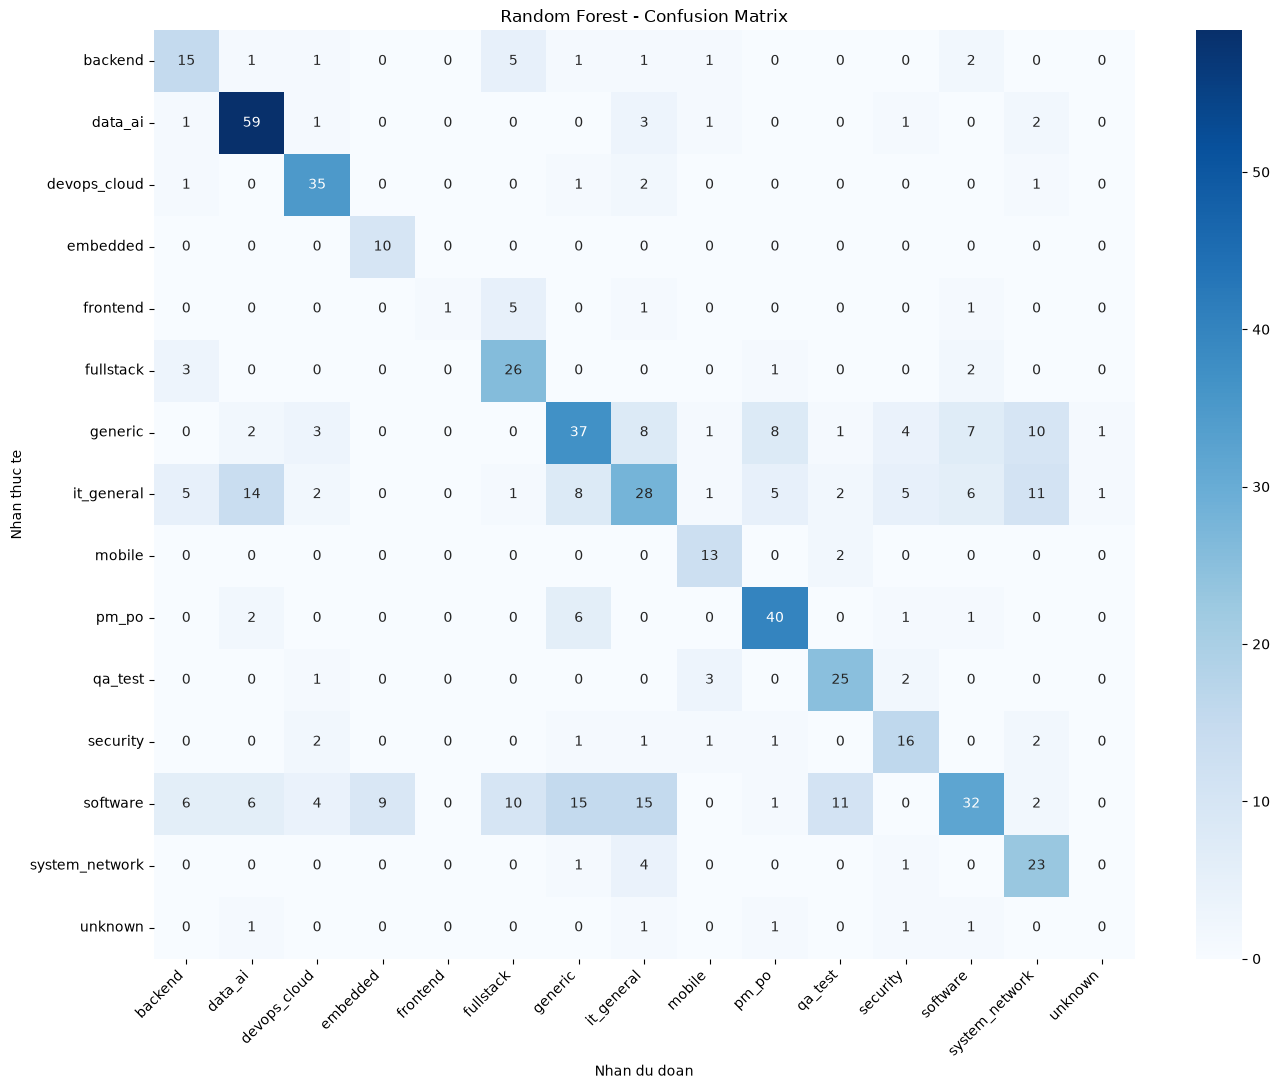

=== HIEU QUA THEO TUNG NHOM NGHE ===


,Nhan,So_mau_test,Du_doan_dung,Recall
3,embedded,10,10,1.0000
2,devops_cloud,40,35,0.8750
1,data_ai,68,59,0.8676
8,mobile,15,13,0.8667
5,fullstack,32,26,0.8125
10,qa_test,31,25,0.8065
9,pm_po,50,40,0.8000
13,system_network,29,23,0.7931
11,security,24,16,0.6667
0,backend,27,15,0.5556


In [34]:

# BUOC 2.5.11.2 - CONFUSION MATRIX RANDOM FOREST

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.metrics import confusion_matrix

# Su dung Pipeline Random Forest da toi uu
y_pred_rf = best_rf.predict(X_test)

# Danh sach 15 nhan
labels = sorted(y_test.unique())

# Tao ma tran nham lan
cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=labels
)

# Truc quan hoa
plt.figure(figsize=(14, 11))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Nhan du doan")
plt.ylabel("Nhan thuc te")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Tinh ty le du doan dung theo tung lop
class_total = cm.sum(axis=1)

class_recall = np.divide(
    np.diag(cm),
    class_total,
    out=np.zeros(len(labels), dtype=float),
    where=class_total != 0
)

class_summary = pd.DataFrame({
    "Nhan": labels,
    "So_mau_test": class_total,
    "Du_doan_dung": np.diag(cm),
    "Recall": class_recall
})

print("=== HIEU QUA THEO TUNG NHOM NGHE ===")
display(
    class_summary.sort_values(
        "Recall", ascending=False
    ).round(4)
)



### Bước 2.5.11.3 – Trực quan hóa nâng cao và phân tích lỗi phân lớp

**Mục đích:** Đánh giá chi tiết khả năng nhận diện 15 nhóm nghề của mô hình Random Forest thông qua ma trận nhầm lẫn chuẩn hóa, Recall theo từng nhóm và các cặp nhãn thường bị dự đoán sai.

**Lý do thực hiện:** Confusion Matrix ở bước 2.5.11.2 thể hiện số lượng dự đoán đúng và sai. Tuy nhiên, số lượng mẫu giữa các nhóm nghề không đồng đều, nên chỉ so sánh số lượng tuyệt đối có thể dẫn đến nhận xét chưa chính xác.

**Phương pháp:**
- Chuẩn hóa ma trận nhầm lẫn theo từng hàng để biểu diễn tỷ lệ phần trăm.
- Tính Recall của từng nhóm nghề và sắp xếp từ thấp đến cao.
- Thống kê 10 cặp nhãn có số lần nhầm lẫn lớn nhất.

**Lưu ý:** Các nhóm có ít mẫu Test có thể có Recall rất cao hoặc rất thấp nhưng chưa phản ánh chắc chắn khả năng tổng quát hóa. Kết quả cần được đối chiếu với số lượng mẫu và quy tắc gán nhãn ở bước 2.1.

**Kết quả mong đợi:** Xác định các nhóm nghề được phân loại tốt, các nhóm dễ nhầm lẫn và những hạn chế cần trình bày trong MiniNote 2.5.


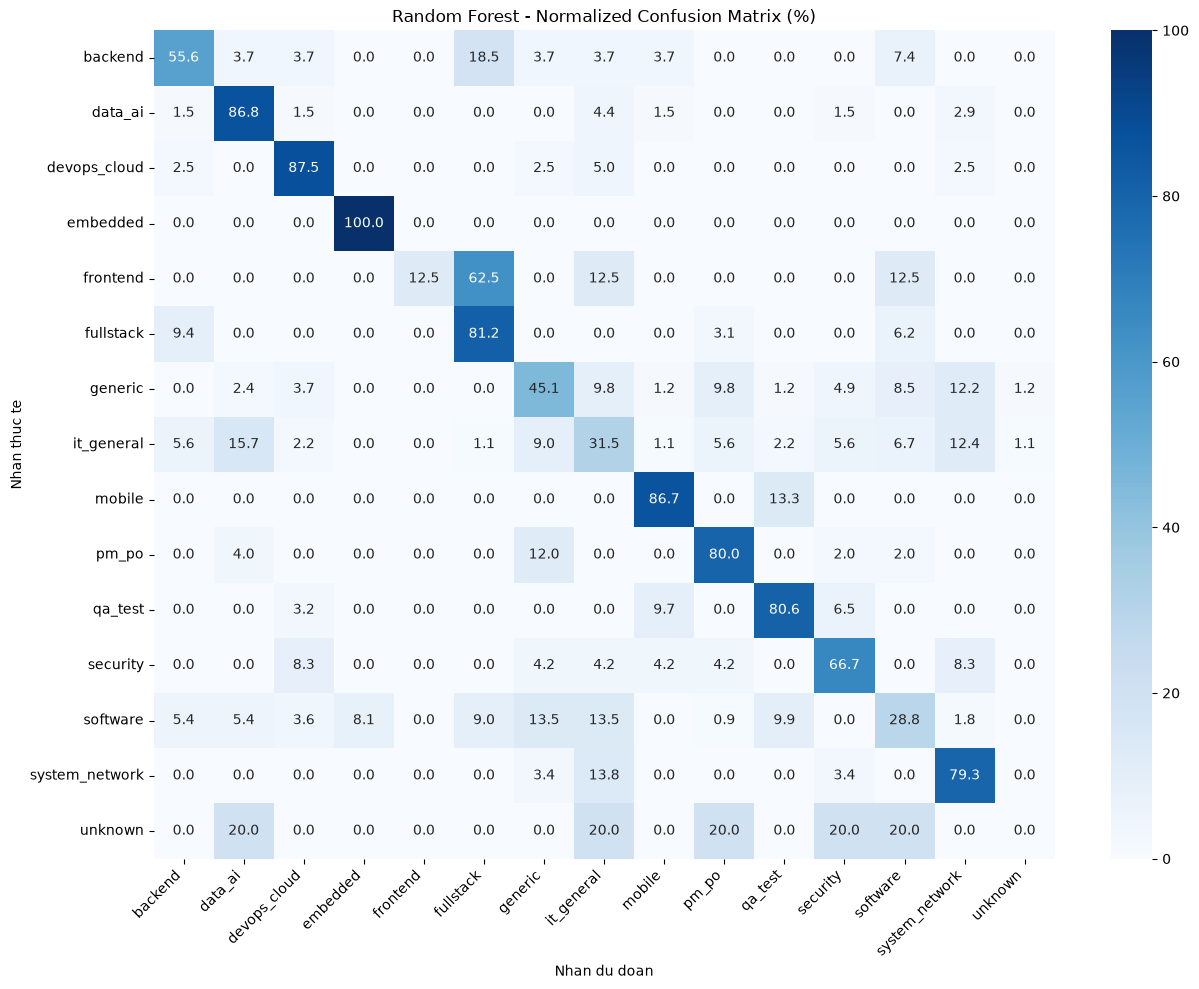

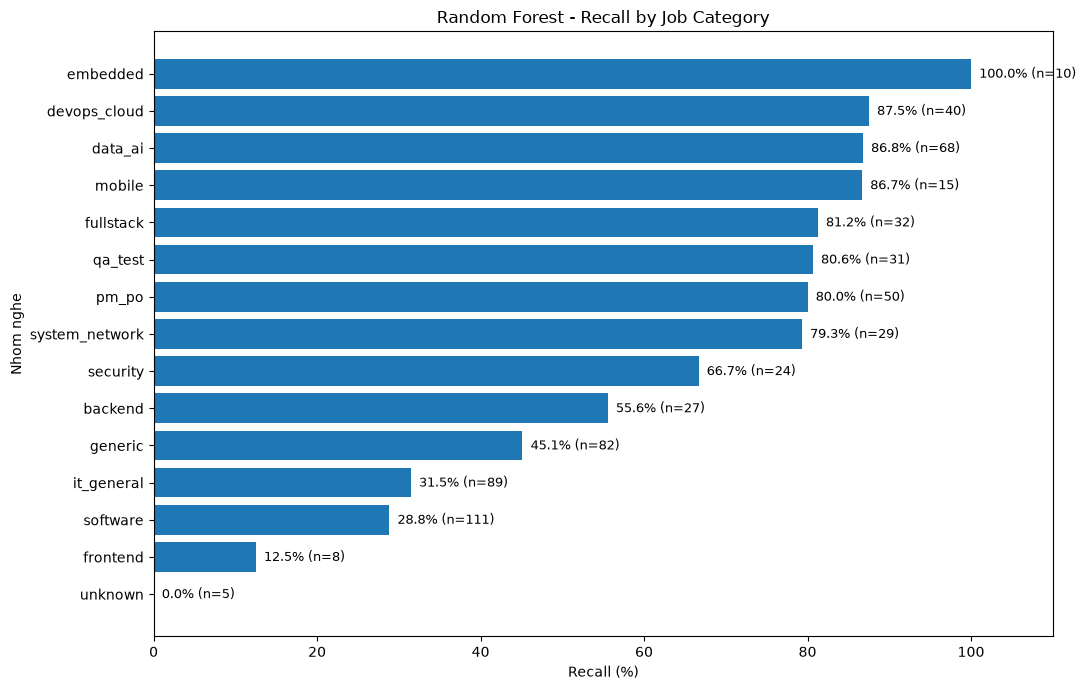

,Nhom_nghe,Recall_%,So_mau_test
14,unknown,0.00,5
4,frontend,12.50,8
12,software,28.83,111
7,it_general,31.46,89
6,generic,45.12,82
0,backend,55.56,27
11,security,66.67,24
13,system_network,79.31,29
9,pm_po,80.00,50
10,qa_test,80.65,31


In [35]:

# BUOC 2.5.11.3 - TRUC QUAN HOA NANG CA

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Lay mo hinh Random Forest tot nhat
best_rf = grid_rf.best_estimator_

# Du doan tren tap Test
y_pred_rf = best_rf.predict(X_test)

# Lay danh sach 15 nhan
labels = sorted(y_test.unique())

# Tao ma tran nham lan
cm = confusion_matrix(y_test, y_pred_rf, labels=labels)

# Chuan hoa theo tung hang (%)
row_totals = cm.sum(axis=1, keepdims=True)

cm_percent = np.divide(
    cm * 100,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

# BIEU DO 1: CONFUSION MATRIX CHUAN HOA
plt.figure(figsize=(13, 10))

sns.heatmap(
    cm_percent,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Random Forest - Normalized Confusion Matrix (%)")
plt.xlabel("Nhan du doan")
plt.ylabel("Nhan thuc te")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Tinh Recall va so mau cua tung nhom
recall_values = np.diag(cm_percent)
support_values = cm.sum(axis=1)

recall_df = pd.DataFrame({
    "Nhom_nghe": labels,
    "Recall_%": recall_values,
    "So_mau_test": support_values
})

recall_df = recall_df.sort_values("Recall_%")

# BIEU DO 2: RECALL THEO NHOM NGHE
plt.figure(figsize=(11, 7))

bars = plt.barh(
    recall_df["Nhom_nghe"],
    recall_df["Recall_%"]
)

plt.xlim(0, 110)
plt.xlabel("Recall (%)")
plt.ylabel("Nhom nghe")
plt.title("Random Forest - Recall by Job Category")

for bar, value, n in zip(
    bars,
    recall_df["Recall_%"],
    recall_df["So_mau_test"]
):
    plt.text(
        value + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}% (n={n})",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

display(recall_df.round(2))


=== TOP 10 CAP NHAN BI NHAM LAN ===


,Nhan_thuc_te,Nhan_du_doan,So_lan_nham
0,software,generic,15
1,software,it_general,15
2,it_general,data_ai,14
3,it_general,system_network,11
4,software,qa_test,11
5,software,fullstack,10
6,generic,system_network,10
7,software,embedded,9
8,it_general,generic,8
9,generic,pm_po,8


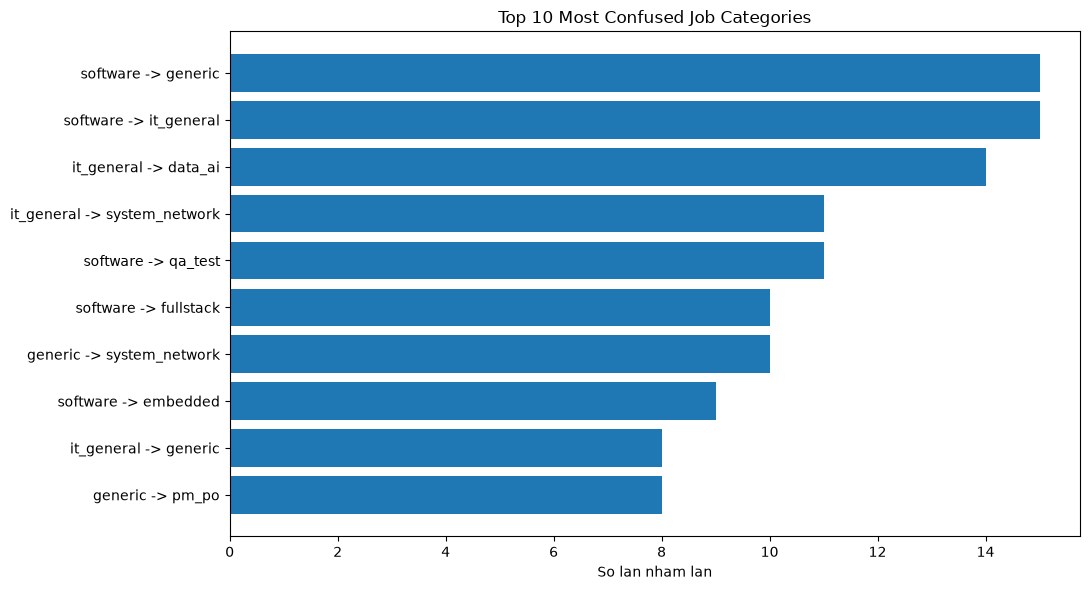

In [36]:

# BUOC 2.5.11.3 - TOP 10 CAP NHAN NHAM LAN

errors = []

for i in range(len(labels)):
    for j in range(len(labels)):

        # Bo qua cac du doan dung
        if i == j:
            continue

        # Chi lay cac cap co nham lan
        if cm[i, j] > 0:
            errors.append({
                "Nhan_thuc_te": labels[i],
                "Nhan_du_doan": labels[j],
                "So_lan_nham": int(cm[i, j])
            })

errors_df = pd.DataFrame(errors)

top_errors = (
    errors_df
    .sort_values("So_lan_nham", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

print("=== TOP 10 CAP NHAN BI NHAM LAN ===")
display(top_errors)

# Ve bieu do
top_errors["Cap_nham_lan"] = (
    top_errors["Nhan_thuc_te"]
    + " -> "
    + top_errors["Nhan_du_doan"]
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_errors["Cap_nham_lan"],
    top_errors["So_lan_nham"]
)

plt.gca().invert_yaxis()
plt.xlabel("So lan nham lan")
plt.title("Top 10 Most Confused Job Categories")
plt.tight_layout()
plt.show()



### Bước 2.5.12 – Tổng hợp kết quả và xuất báo cáo

**Mục đích:** Tổng hợp kết quả phân lớp của ba mô hình, lưu các bảng thống kê và biểu đồ để phục vụ báo cáo bài tập lớn.

**Lý do thực hiện:** Các bước 2.5.8–2.5.11 đã hoàn thành huấn luyện và đánh giá. Tuy nhiên, kết quả hiện chủ yếu được hiển thị trong Notebook. Cần xuất thành các file riêng để các thành viên có thể sử dụng mà không cần chạy lại toàn bộ quá trình huấn luyện.

**Nội dung thực hiện:**
1. Xuất bảng so sánh ba mô hình.
2. Xuất Recall theo từng nhóm nghề.
3. Xuất các cặp nhãn bị nhầm lẫn nhiều nhất.
4. Lưu Confusion Matrix và biểu đồ Recall.
5. Lưu cấu hình mô hình và thông tin thực nghiệm.
6. Kiểm tra các file đầu ra.

**Lưu ý:** Các kết quả được xuất từ mô hình đã huấn luyện, không sử dụng lại tập Test để điều chỉnh tham số. Dữ liệu đầu vào được kế thừa từ bước 2.1–2.2.

**Kết quả mong đợi:** Có đầy đủ file CSV, PNG và thông tin cấu hình để đưa lên GitHub và sử dụng trong báo cáo cuối kỳ.


Tạo thư mục và xuất bảng kết quả

In [ ]:

# BUOC 2.5.12.1 - XUAT BANG KET QUA

from pathlib import Path
import pandas as pd

# Tim thu muc chua Notebook
NOTEBOOK_DIR = Path(DATA_PATH).resolve().parents[3] / "buoc 2.5"

# Neu ten folder khac, su dung vi tri file Notebook
if not NOTEBOOK_DIR.exists():
    NOTEBOOK_DIR = Path.cwd()

# Tao thu muc luu ket qua
OUTPUT_DIR = NOTEBOOK_DIR / "output"
DATA_OUT = OUTPUT_DIR / "data"
FIGURE_OUT = OUTPUT_DIR / "figures"

DATA_OUT.mkdir(parents=True, exist_ok=True)
FIGURE_OUT.mkdir(parents=True, exist_ok=True)

# Xuat bang so sanh mo hinh
comparison_df.to_csv(
    DATA_OUT / "model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

# Xuat Recall theo nhom nghe
recall_df.to_csv(
    DATA_OUT / "recall_by_class.csv",
    index=False,
    encoding="utf-8-sig"
)

# Xuat Top 10 cap nham lan
top_errors.to_csv(
    DATA_OUT / "top_confusion_pairs.csv",
    index=False,
    encoding="utf-8-sig"
)

# Xuat ma tran nham lan
cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

cm_df.to_csv(
    DATA_OUT / "confusion_matrix.csv",
    encoding="utf-8-sig"
)

print("=== XUAT DU LIEU THANH CONG ===")
print("Thu muc:", OUTPUT_DIR)

for file in sorted(DATA_OUT.glob("*.csv")):
    print(file.name)


=== XUAT DU LIEU THANH CONG ===
Thu muc: d:\Projects\BaiTapLon_KhaiPhaDuLieu\vietnam-it-job-market-analysis-main\buoc 2.5\output
confusion_matrix.csv
model_comparison.csv
recall_by_class.csv
top_confusion_pairs.csv


Xuất bộ ba biểu đồ

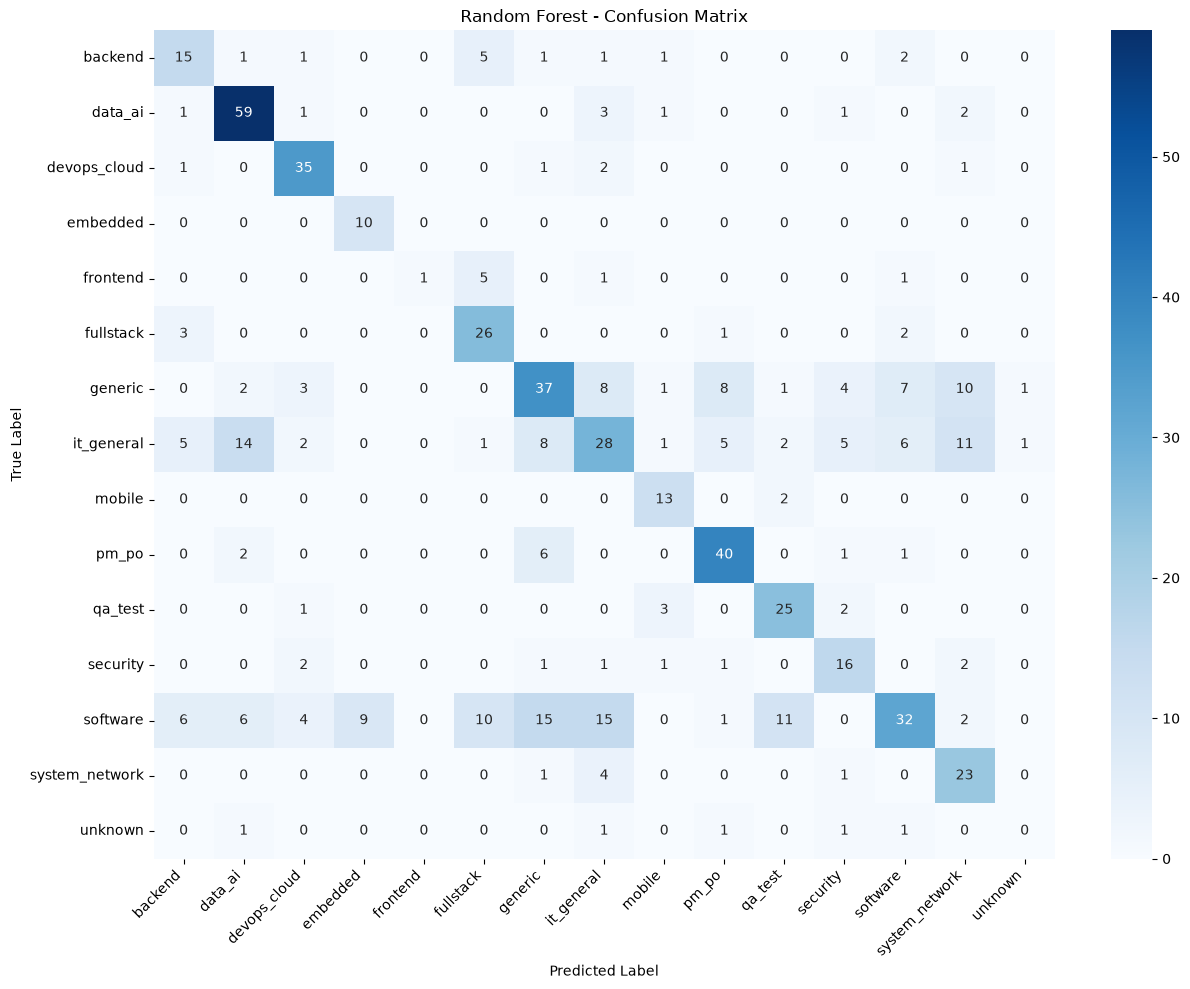

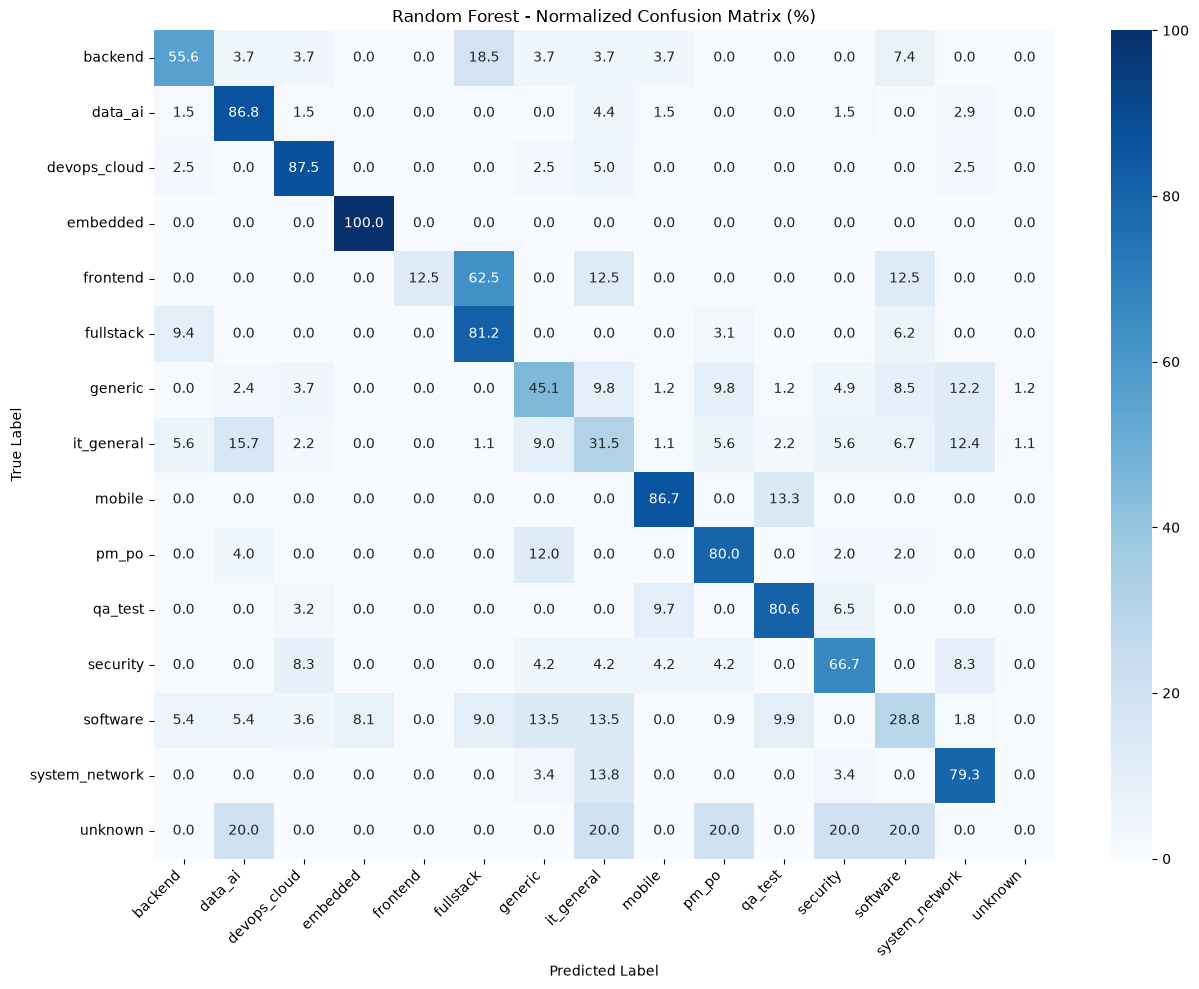

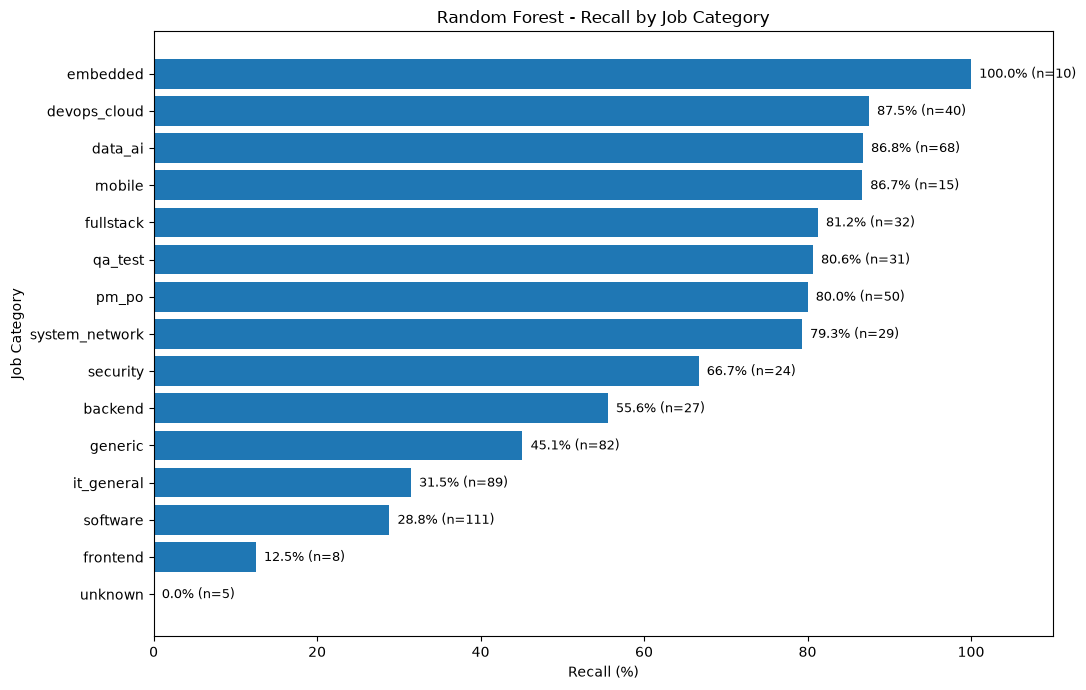

Da luu 3 bieu do PNG.


In [38]:

# BUOC 2.5.12.2 - LUU BIEU DO

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Confusion Matrix goc
plt.figure(figsize=(13, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    FIGURE_OUT / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# 2. Confusion Matrix chuan hoa
row_totals = cm.sum(axis=1, keepdims=True)

cm_percent = np.divide(
    cm * 100,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

plt.figure(figsize=(13, 10))

sns.heatmap(
    cm_percent,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Random Forest - Normalized Confusion Matrix (%)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    FIGURE_OUT / "normalized_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# 3. Recall theo nhom nghe
recall_plot = recall_df.sort_values("Recall_%")

plt.figure(figsize=(11, 7))

bars = plt.barh(
    recall_plot["Nhom_nghe"],
    recall_plot["Recall_%"]
)

plt.xlim(0, 110)
plt.xlabel("Recall (%)")
plt.ylabel("Job Category")
plt.title("Random Forest - Recall by Job Category")

for bar, value, n in zip(
    bars,
    recall_plot["Recall_%"],
    recall_plot["So_mau_test"]
):
    plt.text(
        value + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}% (n={n})",
        va="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    FIGURE_OUT / "recall_by_class.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Da luu 3 bieu do PNG.")


Lưu cấu hình và kiểm tra file

In [39]:

# BUOC 2.5.12.3 - LUU THONG TIN THUC NGHIEM

import json
from datetime import datetime

experiment_info = {
    "dataset": DATA_PATH.name,
    "total_samples": int(len(df)),
    "train_samples": int(len(y_train)),
    "test_samples": int(len(y_test)),
    "num_classes": int(y_test.nunique()),
    "best_model": "Random Forest",
    "decision_tree_params": grid_dt.best_params_,
    "random_forest_params": grid_rf.best_params_,
    "random_forest_cv_macro_f1": float(grid_rf.best_score_),
    "created_at": datetime.now().isoformat(timespec="seconds")
}

config_path = OUTPUT_DIR / "experiment_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(
        experiment_info,
        f,
        ensure_ascii=False,
        indent=4
    )

print("=== DANH SACH FILE DA XUAT ===")

for file in sorted(OUTPUT_DIR.rglob("*")):
    if file.is_file():
        print(file.relative_to(OUTPUT_DIR))

print("\nHoan thanh buoc 2.5.12!")


=== DANH SACH FILE DA XUAT ===
data\confusion_matrix.csv
data\model_comparison.csv
data\recall_by_class.csv
data\top_confusion_pairs.csv
experiment_config.json
figures\confusion_matrix.png
figures\normalized_confusion_matrix.png
figures\recall_by_class.png

Hoan thanh buoc 2.5.12!
